## Testing how well the models fit
Could also be used to change e.g. size of network, but now worked on a brief proof of concept to train all models (in parallel) and compare them.




In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
from pathlib import Path
from halcyon.Simulators.GNWSimRunner import GNWSimRunner, SimulationResult
from halcyon.Datasets.ExpressionDataWithConditions import ExpressionDataWithConditions
from halcyon.Models.NeuralODE import PhoenixOnlyAddLayers, PhoenixAddAndProdLayers
from halcyon.Models.CellBox import CellBox

from halcyon.Trainer import Trainer
# import torch.multiprocessing as mp
import multiprocessing as mp

from halcyon.Trainer import TrainingJob, run_training_job

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from halcyon.Datasets.ExpressionData import ExpressionData

import logging


logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

## Data generation

In [5]:
sim_outputs = []
for nr_genes in [8, 16]: #, 20, 50, 100]:
    for nr_modules in [4]: #, 5, 10]:
        for sparsity in [0.1,]: # 0.25, 0.5]:
            gnw_sim = GNWSimRunner(
                settings_path=Path("../setting_files/gnw_testing_runs_settings.txt"),
            )
            generated_data_path = Path("../data/fitting_on_multiple_sim_settings") / f"genes_{nr_genes}_modules_{nr_modules}_sparsity_{sparsity}"
            generated_data_path.mkdir(parents=True, exist_ok=True)
            network_name = 'my_network'
            sim_result = gnw_sim.run_simulation(
                n_genes=nr_genes,
                sparsity=sparsity,
                num_modules=nr_modules,
                network_name=network_name,
                output_path=generated_data_path,
            )           
            sim_outputs.append(sim_result) 

2025-10-01 14:11:13,699 - INFO - Generating network


Loading specified settings: ../setting_files/gnw_testing_runs_settings.txt
Done
Start network creation of type MODULAR_SCALEFREE
Setting dynamical model for my_network

Random initialization of my_network
my_network: Node_0: (Node_0) + ~(Node_4)
my_network: Node_1: ~(Node_1~Node_3)
my_network: Node_2: (Node_2*Node_5)
my_network: Node_3: (Node_3) + ~(Node_1)
my_network: Node_4: ~(Node_0~Node_4)
my_network: Node_5: (Node_2*Node_5)
my_network: Node_6: (Node_2) + ~(Node_5)
my_network: Node_7: ~(Node_1)
Writing file /lustre/BIF/nobackup/noord087/phd/HALCYON/notebooks/../data/fitting_on_multiple_sim_settings/genes_8_modules_4_sparsity_0.1/my_network.xml

Thomas Schaffter (thomas.schaff...@gmail.com)
Daniel Marbach (daniel.marb...@gmail.com)
Gilles Roulet (gilles.rou...@gmail.com)

http://tschaffter.ch/projects/gnw
2025-10-01 14:11:14,366 - INFO - Simulating network expression over time
2025-10-01 14:11:15,336 - INFO - Generating network
Loading specified settings: ../setting_files/gnw_testin

In [6]:
sim_outputs

[SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/fitting_on_multiple_sim_settings/genes_8_modules_4_sparsity_0.1'), network_name='my_network', nr_genes=8, nr_modules=4, sparsity=0.1, keep_self_interactions=True),
 SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/fitting_on_multiple_sim_settings/genes_16_modules_4_sparsity_0.1'), network_name='my_network', nr_genes=16, nr_modules=4, sparsity=0.1, keep_self_interactions=True)]

## Model fitting

In [7]:
devices = ["cuda:0", "cuda:1"]
train_jobs = []
train_steps = 50
train_jobs.extend([
    TrainingJob(PhoenixOnlyAddLayers, sim_result, nr_training_steps=train_steps, model_kwargs={'device':devices[i % len(devices)]}, optimizer_kwargs={'lr': .1})
    for i, sim_result in enumerate(sim_outputs)
])
train_jobs.extend([
    TrainingJob(PhoenixAddAndProdLayers, sim_result, nr_training_steps=train_steps, model_kwargs={'device':devices[i % len(devices)], 'hidden_size': 16}, optimizer_kwargs={'lr': .1})
    for i, sim_result in enumerate(sim_outputs)
])

train_jobs.extend([
    TrainingJob(CellBox, sim_result, nr_training_steps=train_steps, model_kwargs={'device':devices[i % len(devices)]}, optimizer_kwargs={'lr': .1})
    for i, sim_result in enumerate(sim_outputs)
])


In [8]:
mp.set_start_method("spawn", force=True)  
with mp.Pool(processes=4) as pool:
    train_outputs = pool.map(run_training_job, train_jobs)

2025-10-01 14:12:20,015 [SpawnPoolWorker-2] Epoch 0, loss 0.10172314941883087
2025-10-01 14:12:20,287 [SpawnPoolWorker-3] Epoch 0, loss 0.14599284529685974
2025-10-01 14:12:21,857 [SpawnPoolWorker-2] Epoch 1, loss 0.09784578531980515
2025-10-01 14:12:21,865 [SpawnPoolWorker-4] Epoch 0, loss 0.04486788064241409
2025-10-01 14:12:23,915 [SpawnPoolWorker-2] Epoch 2, loss 0.0937858447432518
2025-10-01 14:12:24,033 [SpawnPoolWorker-1] Epoch 0, loss 0.08568774908781052
2025-10-01 14:12:26,127 [SpawnPoolWorker-2] Epoch 3, loss 0.08850431442260742
2025-10-01 14:12:28,236 [SpawnPoolWorker-2] Epoch 4, loss 0.08368449658155441
2025-10-01 14:12:29,826 [SpawnPoolWorker-4] Epoch 1, loss 0.06373599171638489
2025-10-01 14:12:29,901 [SpawnPoolWorker-3] Epoch 1, loss 0.7905347347259521
2025-10-01 14:12:30,351 [SpawnPoolWorker-2] Epoch 5, loss 0.0800001323223114
2025-10-01 14:12:32,377 [SpawnPoolWorker-3] Epoch 2, loss 0.12695962190628052
2025-10-01 14:12:32,497 [SpawnPoolWorker-2] Epoch 6, loss 0.0769222

In [9]:
train_outputs

[{'final_loss': 0.004941781982779503,
  'nr_training_steps': 50,
  'model_path': '/lustre/BIF/nobackup/noord087/phd/HALCYON/data/fitting_on_multiple_sim_settings/genes_8_modules_4_sparsity_0.1/trained_PhoenixOnlyAddLayers.pt',
  'model_cls': 'PhoenixOnlyAddLayers',
  'data_path': PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/fitting_on_multiple_sim_settings/genes_8_modules_4_sparsity_0.1'),
  'network_name': 'my_network',
  'nr_genes': 8,
  'nr_modules': 4,
  'sparsity': 0.1,
  'keep_self_interactions': True},
 {'final_loss': 0.016867073252797127,
  'nr_training_steps': 50,
  'model_path': '/lustre/BIF/nobackup/noord087/phd/HALCYON/data/fitting_on_multiple_sim_settings/genes_16_modules_4_sparsity_0.1/trained_PhoenixOnlyAddLayers.pt',
  'model_cls': 'PhoenixOnlyAddLayers',
  'data_path': PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/fitting_on_multiple_sim_settings/genes_16_modules_4_sparsity_0.1'),
  'network_name': 'my_network',
  'nr_genes': 16,
  'nr_modules'

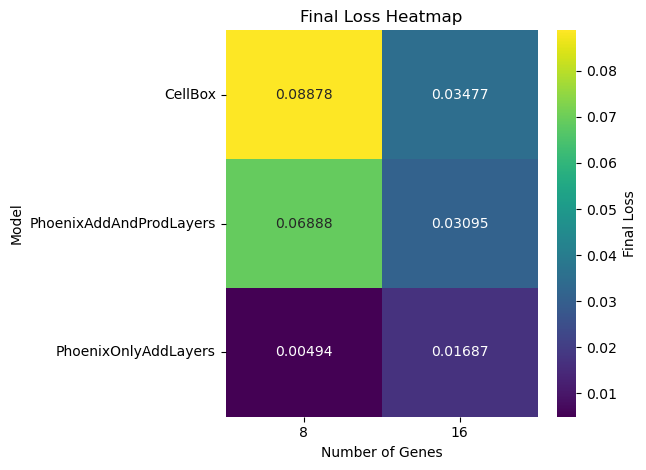

In [12]:
# Assuming `results` is a list of dicts
df = pd.DataFrame(train_outputs)

# Pivot so genes = columns, modules = rows
heatmap_data = df.pivot_table(
    index="model_cls",
    columns="nr_genes",
    values="final_loss",
    aggfunc="mean"
)

sns.heatmap(
    heatmap_data,
    annot=True,        # write values in the cells
    fmt=".5f",         # number format
    cmap="viridis",    # colour map
    cbar_kws={"label": "Final Loss"}
)
plt.xlabel("Number of Genes")
plt.ylabel("Model")
plt.title("Final Loss Heatmap")
plt.tight_layout()
plt.show()